# Black-Scholes Live Pricing — Indian Stocks (NSE)

This notebook pulls **live market data** for Indian equities using `yfinance` and runs a complete Black-Scholes analysis:

- Current spot price from NSE
- Historical volatility estimated from daily log-returns
- Configurable risk-free rate (India 10Y / RBI repo proxy)
- Full option prices + Greeks
- Heatmaps, sensitivity plots, and interactive controls

**Ticker convention**  
- NSE stocks → `SYMBOL.NS`  (e.g. `RELIANCE.NS`, `TCS.NS`)  
- BSE stocks → `SYMBOL.BO`

## 1. Install / Import

In [1]:
# Uncomment if needed
# !pip install yfinance ipywidgets -q

import warnings
warnings.filterwarnings("ignore")

import numpy as np
from numpy import log, sqrt, exp
from scipy.stats import norm
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from datetime import datetime, timedelta

try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output, HTML
    HAS_WIDGETS = True
except ImportError:
    HAS_WIDGETS = False
    print("ipywidgets not found – interactive section will be limited.")

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("viridis")
%matplotlib inline

print("Libraries ready.")
print(f"yfinance version: {yf.__version__}")

Libraries ready.
yfinance version: 1.5.2


## 2. Black-Scholes Engine

Same production-quality class as before (prices + all major Greeks).

In [2]:
class BlackScholes:
    """European option pricer (Black-Scholes-Merton, no dividends)."""

    def __init__(self, S: float, K: float, T: float, r: float, sigma: float):
        if T <= 0 or sigma <= 0 or S <= 0 or K <= 0:
            raise ValueError("S, K, T, sigma must all be positive")
        self.S, self.K, self.T, self.r, self.sigma = map(float, (S, K, T, r, sigma))
        self._d1 = (log(self.S / self.K) + (self.r + 0.5 * self.sigma**2) * self.T) / (
            self.sigma * sqrt(self.T)
        )
        self._d2 = self._d1 - self.sigma * sqrt(self.T)
        self._df  = exp(-self.r * self.T)

    @property
    def call_price(self):
        return self.S * norm.cdf(self._d1) - self.K * self._df * norm.cdf(self._d2)

    @property
    def put_price(self):
        return self.K * self._df * norm.cdf(-self._d2) - self.S * norm.cdf(-self._d1)

    @property
    def call_delta(self):
        return norm.cdf(self._d1)

    @property
    def put_delta(self):
        return norm.cdf(self._d1) - 1.0

    @property
    def gamma(self):
        return norm.pdf(self._d1) / (self.S * self.sigma * sqrt(self.T))

    @property
    def vega(self):
        """Per 1% change in volatility."""
        return self.S * norm.pdf(self._d1) * sqrt(self.T) / 100.0

    @property
    def call_theta(self):
        """Per calendar day."""
        t1 = -(self.S * norm.pdf(self._d1) * self.sigma) / (2 * sqrt(self.T))
        t2 = -self.r * self.K * self._df * norm.cdf(self._d2)
        return (t1 + t2) / 365.0

    @property
    def put_theta(self):
        t1 = -(self.S * norm.pdf(self._d1) * self.sigma) / (2 * sqrt(self.T))
        t2 =  self.r * self.K * self._df * norm.cdf(-self._d2)
        return (t1 + t2) / 365.0

    @property
    def call_rho(self):
        return self.K * self.T * self._df * norm.cdf(self._d2) / 100.0

    @property
    def put_rho(self):
        return -self.K * self.T * self._df * norm.cdf(-self._d2) / 100.0

    def summary(self) -> pd.DataFrame:
        rows = [
            ("Call Price", self.call_price),
            ("Put Price",  self.put_price),
            ("Call Delta", self.call_delta),
            ("Put Delta",  self.put_delta),
            ("Gamma",      self.gamma),
            ("Vega (1%)",  self.vega),
            ("Call Theta (day)", self.call_theta),
            ("Put Theta (day)",  self.put_theta),
            ("Call Rho (1%)", self.call_rho),
            ("Put Rho (1%)",  self.put_rho),
        ]
        df = pd.DataFrame(rows, columns=["Metric", "Value"])
        df["Value"] = df["Value"].round(6)
        return df

    def __repr__(self):
        return f"BlackScholes(S={self.S:.2f}, K={self.K:.2f}, T={self.T}, r={self.r}, σ={self.sigma:.4f})"

## 3. Live Data Helpers (yfinance)

In [3]:
# Popular NSE stocks for quick selection
POPULAR_NSE = {
    "Reliance Industries": "RELIANCE.NS",
    "TCS": "TCS.NS",
    "Infosys": "INFY.NS",
    "HDFC Bank": "HDFCBANK.NS",
    "ICICI Bank": "ICICIBANK.NS",
    "SBI": "SBIN.NS",
    "Bharti Airtel": "BHARTIARTL.NS",
    "ITC": "ITC.NS",
    "Hindustan Unilever": "HINDUNILVR.NS",
    "Larsen & Toubro": "LT.NS",
    "Axis Bank": "AXISBANK.NS",
    "Kotak Mahindra Bank": "KOTAKBANK.NS",
    "Bajaj Finance": "BAJFINANCE.NS",
    "Asian Paints": "ASIANPAINT.NS",
    "Maruti Suzuki": "MARUTI.NS",
    "Tata Motors": "TATAMOTORS.NS",
    "Sun Pharma": "SUNPHARMA.NS",
    "Wipro": "WIPRO.NS",
    "HCL Tech": "HCLTECH.NS",
    "NTPC": "NTPC.NS",
}


def fetch_stock_data(ticker: str, lookback_days: int = 252):
    """
    Pull OHLCV history and return:
      - last close (spot)
      - annualized historical volatility
      - full history DataFrame
      - short name if available
    """
    ticker = ticker.strip().upper()
    if not (ticker.endswith(".NS") or ticker.endswith(".BO")):
        # Assume NSE if user forgot suffix
        ticker = ticker + ".NS"

    stock = yf.Ticker(ticker)
    hist = stock.history(period=f"{lookback_days + 30}d")  # a bit extra buffer

    if hist.empty or len(hist) < 20:
        raise ValueError(f"Could not fetch enough history for {ticker}. Check the symbol.")

    hist = hist.dropna(subset=["Close"])
    spot = float(hist["Close"].iloc[-1])

    # Annualized volatility from daily log returns
    log_ret = np.log(hist["Close"] / hist["Close"].shift(1)).dropna()
    # Use last `lookback_days` trading days if available
    log_ret = log_ret.tail(lookback_days)
    hist_vol = float(log_ret.std() * np.sqrt(252))

    # Try to get a friendly name
    name = ticker
    try:
        info = stock.info
        name = info.get("shortName") or info.get("longName") or ticker
    except Exception:
        pass

    return {
        "ticker": ticker,
        "name": name,
        "spot": spot,
        "hist_vol": hist_vol,
        "history": hist,
        "n_days": len(log_ret),
        "as_of": hist.index[-1].strftime("%Y-%m-%d"),
    }


def print_live_snapshot(data: dict, r: float):
    print("=" * 55)
    print(f"  {data['name']}  ({data['ticker']})")
    print(f"  As of           : {data['as_of']}")
    print(f"  Spot (Close)    : ₹ {data['spot']:,.2f}")
    print(f"  Hist. Vol (ann.): {data['hist_vol']:.2%}   ({data['n_days']} trading days)")
    print(f"  Risk-free rate  : {r:.2%}")
    print("=" * 55)

## 4. Choose a Stock & Pull Live Data

Change the ticker below or pick from the popular list.  
Default risk-free rate is set to **6.75%** (approximate India 10Y / policy rate level — adjust as needed).

  RELIANCE INDUSTRIES LTD  (RELIANCE.NS)
  As of           : 2026-10-29
  Spot (Close)    : ₹ 1,167.40
  Hist. Vol (ann.): 21.37%   (252 trading days)
  Risk-free rate  : 6.75%


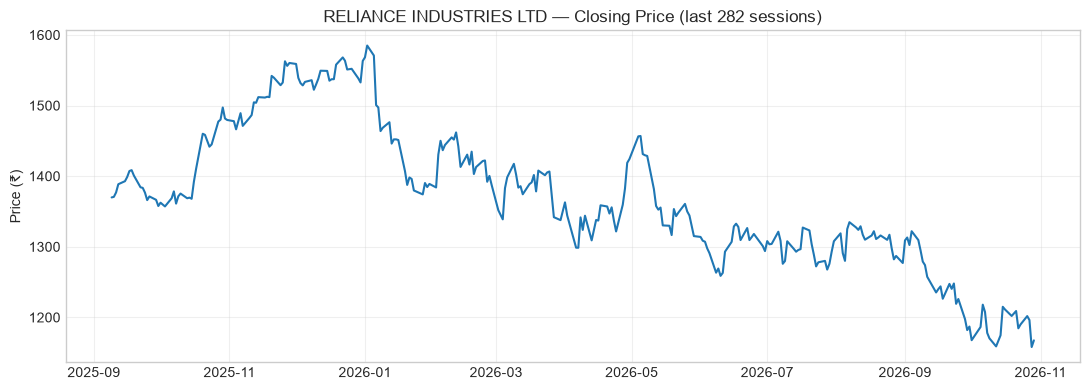

In [4]:
# ---------- USER INPUTS ----------
TICKER        = "RELIANCE.NS"   # change this
LOOKBACK_DAYS = 252             # ~1 year for volatility
RISK_FREE     = 0.0675          # 6.75% – edit to current India rate
# ---------------------------------

data = fetch_stock_data(TICKER, lookback_days=LOOKBACK_DAYS)
print_live_snapshot(data, RISK_FREE)

# Quick price chart
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(data["history"].index, data["history"]["Close"], lw=1.5, color="#1f77b4")
ax.set_title(f"{data['name']} — Closing Price (last {len(data['history'])} sessions)")
ax.set_ylabel("Price (₹)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Price a Specific Option with Live Spot & Vol

Set your desired strike and time-to-maturity.  
Volatility defaults to the live historical estimate; you can override it.

In [5]:
# ---------- OPTION PARAMETERS ----------
STRIKE          = round(data["spot"] / 50) * 50   # nearest 50 for convenience
TIME_TO_MATURITY = 0.25                           # 3 months
VOL_OVERRIDE    = None                            # set e.g. 0.25 to override hist vol
# ---------------------------------------

S     = data["spot"]
sigma = VOL_OVERRIDE if VOL_OVERRIDE is not None else data["hist_vol"]
K     = STRIKE
T     = TIME_TO_MATURITY
r     = RISK_FREE

bs = BlackScholes(S=S, K=K, T=T, r=r, sigma=sigma)

print(f"\nPricing {data['ticker']} option")
print(f"  Spot S     = ₹{S:,.2f}")
print(f"  Strike K   = ₹{K:,.2f}   (moneyness S/K = {S/K:.3f})")
print(f"  T          = {T:.2f} years")
print(f"  σ          = {sigma:.2%}")
print(f"  r          = {r:.2%}\n")

display(bs.summary())


Pricing RELIANCE.NS option
  Spot S     = ₹1,167.40
  Strike K   = ₹1,150.00   (moneyness S/K = 1.015)
  T          = 0.25 years
  σ          = 21.37%
  r          = 6.75%



,Metric,Value
0,Call Price,69.435373
1,Put Price,32.791922
2,Call Delta,0.637558
3,Put Delta,-0.362442
4,Gamma,0.003007
5,Vega (1%),2.188788
6,Call Theta (day),-0.381059
7,Put Theta (day),-0.171947
8,Call Rho (1%),1.687124
9,Put Rho (1%),-1.139767


### Put-Call Parity check (live numbers)

In [6]:
lhs = bs.call_price - bs.put_price
rhs = bs.S - bs.K * exp(-bs.r * bs.T)
print(f"C − P          = {lhs:,.4f}")
print(f"S − K·e^(−rT)  = {rhs:,.4f}")
print(f"Difference     = {abs(lhs-rhs):.2e}")
assert np.isclose(lhs, rhs, atol=1e-8)
print("✓ Put-Call parity holds.")

C − P          = 36.6435
S − K·e^(−rT)  = 36.6435
Difference     = 5.68e-14
✓ Put-Call parity holds.


## 6. Price vs Spot (using live vol & rate)

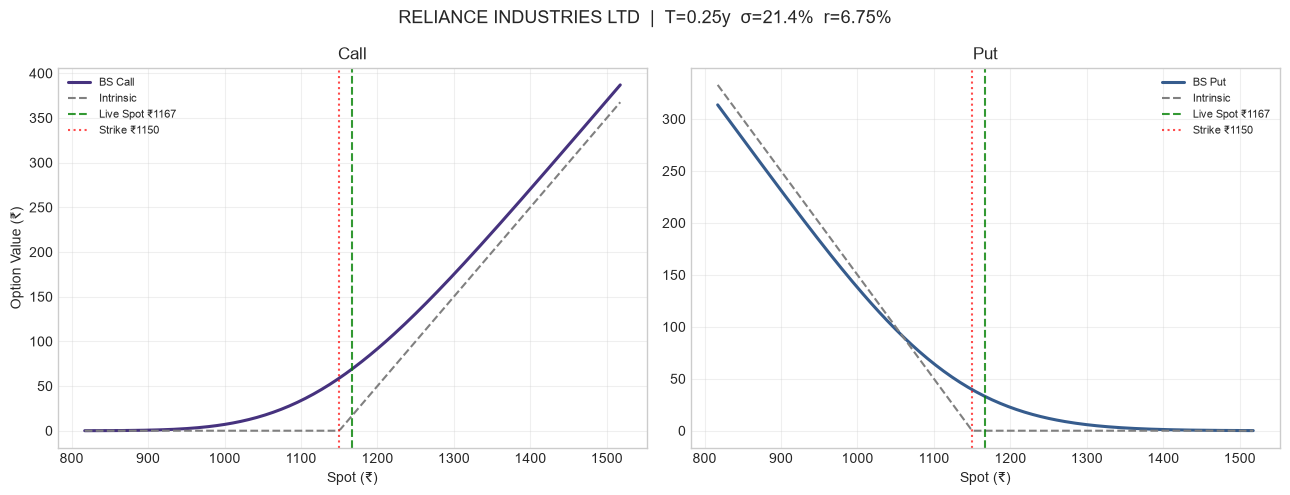

In [7]:
def plot_live_price_curves(S0, K, T, r, sigma, name=""):
    S_range = np.linspace(S0 * 0.7, S0 * 1.3, 200)
    calls = [BlackScholes(s, K, T, r, sigma).call_price for s in S_range]
    puts  = [BlackScholes(s, K, T, r, sigma).put_price  for s in S_range]

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    axes[0].plot(S_range, calls, lw=2.2, label="BS Call")
    axes[0].plot(S_range, np.maximum(S_range - K, 0), "--", color="gray", label="Intrinsic")
    axes[0].axvline(S0, color="green", ls="--", alpha=0.8, label=f"Live Spot ₹{S0:.0f}")
    axes[0].axvline(K,  color="red",   ls=":",  alpha=0.7, label=f"Strike ₹{K:.0f}")
    axes[0].set_title("Call")
    axes[0].legend(fontsize=8)
    axes[0].set_xlabel("Spot (₹)")
    axes[0].set_ylabel("Option Value (₹)")

    axes[1].plot(S_range, puts, lw=2.2, color="C1", label="BS Put")
    axes[1].plot(S_range, np.maximum(K - S_range, 0), "--", color="gray", label="Intrinsic")
    axes[1].axvline(S0, color="green", ls="--", alpha=0.8, label=f"Live Spot ₹{S0:.0f}")
    axes[1].axvline(K,  color="red",   ls=":",  alpha=0.7, label=f"Strike ₹{K:.0f}")
    axes[1].set_title("Put")
    axes[1].legend(fontsize=8)
    axes[1].set_xlabel("Spot (₹)")

    for ax in axes:
        ax.grid(True, alpha=0.3)

    plt.suptitle(f"{name}  |  T={T:.2f}y  σ={sigma:.1%}  r={r:.2%}", fontsize=13)
    plt.tight_layout()
    plt.show()

plot_live_price_curves(S, K, T, r, sigma, name=data["name"])

## 7. Live Greeks vs Spot

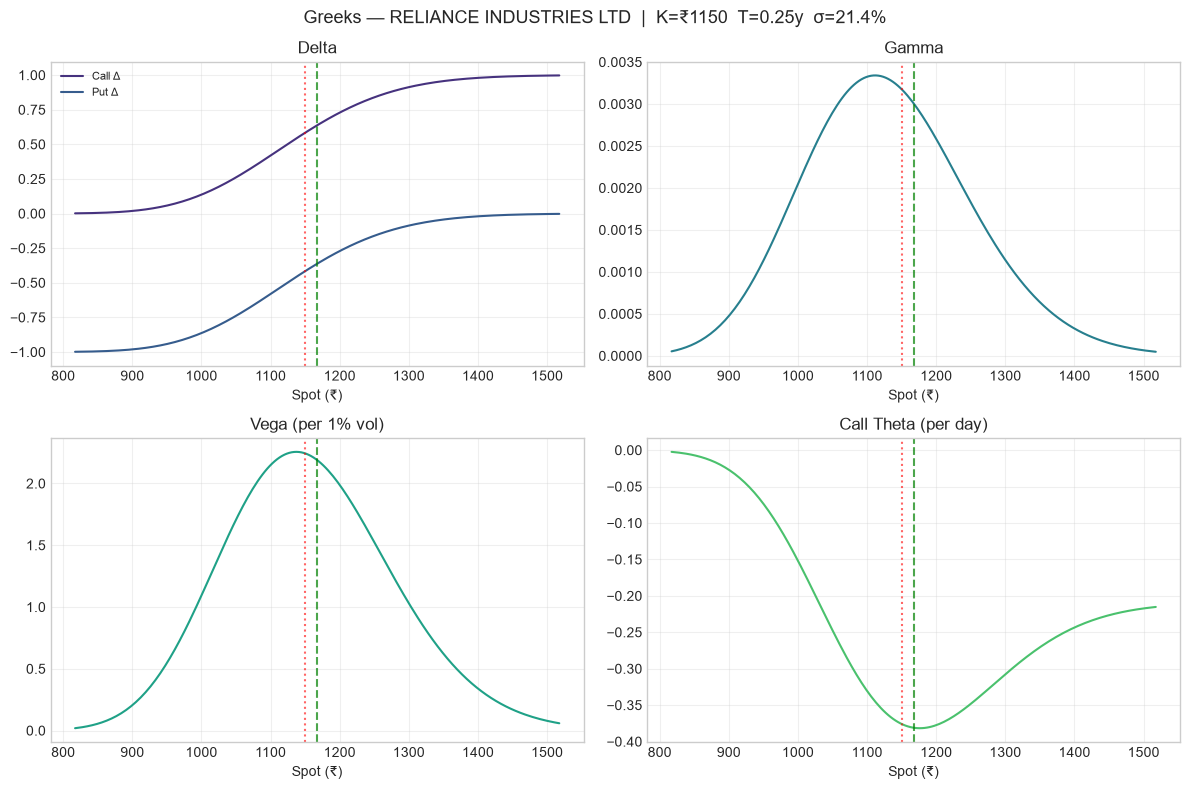

In [8]:
def plot_live_greeks(S0, K, T, r, sigma, name=""):
    S_range = np.linspace(S0 * 0.7, S0 * 1.3, 200)
    deltas_c, deltas_p, gammas, vegas, thetas_c = [], [], [], [], []

    for s in S_range:
        m = BlackScholes(s, K, T, r, sigma)
        deltas_c.append(m.call_delta)
        deltas_p.append(m.put_delta)
        gammas.append(m.gamma)
        vegas.append(m.vega)
        thetas_c.append(m.call_theta)

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    axes[0,0].plot(S_range, deltas_c, label="Call Δ")
    axes[0,0].plot(S_range, deltas_p, label="Put Δ")
    axes[0,0].axvline(S0, color="green", ls="--", alpha=0.7)
    axes[0,0].axvline(K,  color="red",   ls=":",  alpha=0.6)
    axes[0,0].set_title("Delta"); axes[0,0].legend(fontsize=8)

    axes[0,1].plot(S_range, gammas, color="C2")
    axes[0,1].axvline(S0, color="green", ls="--", alpha=0.7)
    axes[0,1].axvline(K,  color="red",   ls=":",  alpha=0.6)
    axes[0,1].set_title("Gamma")

    axes[1,0].plot(S_range, vegas, color="C3")
    axes[1,0].axvline(S0, color="green", ls="--", alpha=0.7)
    axes[1,0].axvline(K,  color="red",   ls=":",  alpha=0.6)
    axes[1,0].set_title("Vega (per 1% vol)")

    axes[1,1].plot(S_range, thetas_c, color="C4")
    axes[1,1].axvline(S0, color="green", ls="--", alpha=0.7)
    axes[1,1].axvline(K,  color="red",   ls=":",  alpha=0.6)
    axes[1,1].set_title("Call Theta (per day)")

    for ax in axes.flat:
        ax.set_xlabel("Spot (₹)")
        ax.grid(True, alpha=0.3)

    plt.suptitle(f"Greeks — {name}  |  K=₹{K:.0f}  T={T:.2f}y  σ={sigma:.1%}", fontsize=13)
    plt.tight_layout()
    plt.show()

plot_live_greeks(S, K, T, r, sigma, name=data["name"])

## 8. Live Heatmaps (Spot × Volatility)

Exactly the same style as the original Streamlit dashboard, now driven by live Indian stock data.

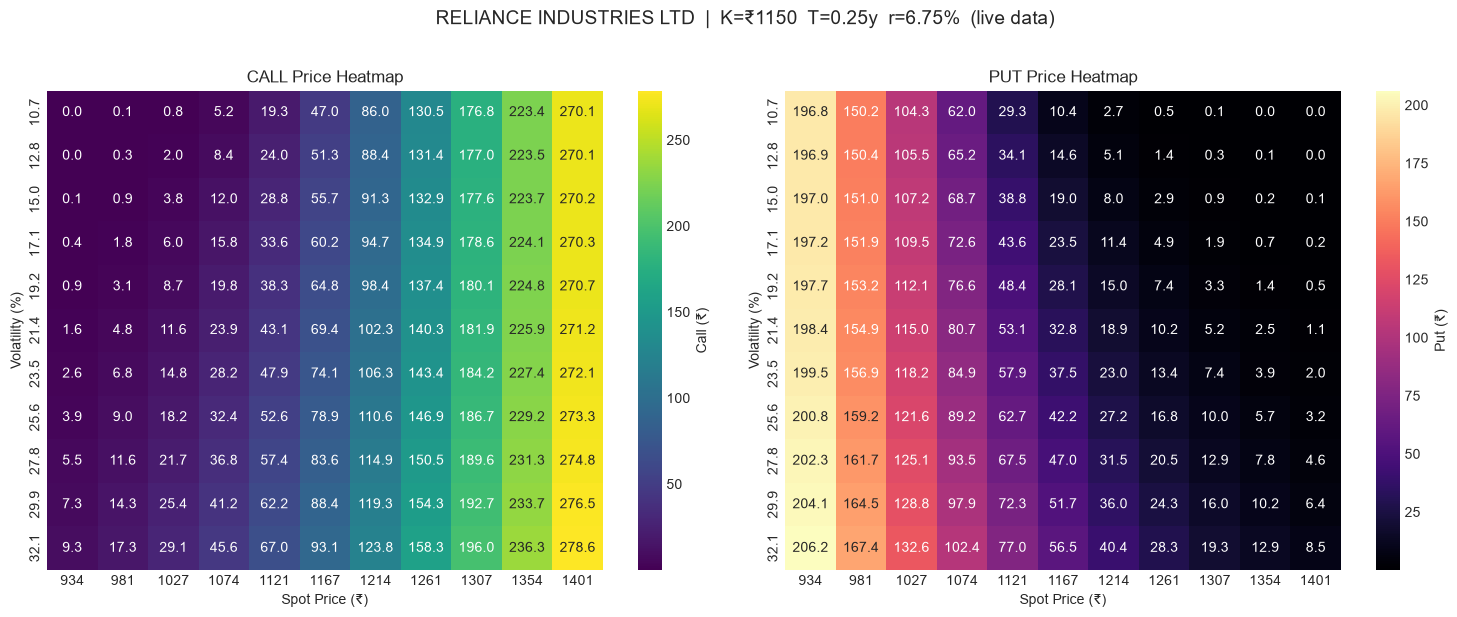

In [9]:
def plot_live_heatmaps(S0, K, T, r, sigma_center,
                       spot_pct=0.20, vol_pct=0.50, n=11, name=""):
    spot_range = np.linspace(S0 * (1 - spot_pct), S0 * (1 + spot_pct), n)
    vol_range  = np.linspace(max(0.05, sigma_center * (1 - vol_pct)),
                             sigma_center * (1 + vol_pct), n)

    call_m = np.zeros((n, n))
    put_m  = np.zeros((n, n))

    for i, vol in enumerate(vol_range):
        for j, s in enumerate(spot_range):
            m = BlackScholes(s, K, T, r, vol)
            call_m[i, j] = m.call_price
            put_m[i, j]  = m.put_price

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    sns.heatmap(call_m,
                xticklabels=np.round(spot_range, 0).astype(int),
                yticklabels=np.round(vol_range * 100, 1),
                annot=True, fmt=".1f", cmap="viridis", ax=axes[0],
                cbar_kws={"label": "Call (₹)"})
    axes[0].set_title("CALL Price Heatmap")
    axes[0].set_xlabel("Spot Price (₹)")
    axes[0].set_ylabel("Volatility (%)")

    sns.heatmap(put_m,
                xticklabels=np.round(spot_range, 0).astype(int),
                yticklabels=np.round(vol_range * 100, 1),
                annot=True, fmt=".1f", cmap="magma", ax=axes[1],
                cbar_kws={"label": "Put (₹)"})
    axes[1].set_title("PUT Price Heatmap")
    axes[1].set_xlabel("Spot Price (₹)")
    axes[1].set_ylabel("Volatility (%)")

    plt.suptitle(
        f"{name}  |  K=₹{K:.0f}  T={T:.2f}y  r={r:.2%}  (live data)",
        fontsize=14, y=1.02
    )
    plt.tight_layout()
    plt.show()

plot_live_heatmaps(S, K, T, r, sigma, name=data["name"])

## 9. Option Chain Style Grid (multiple strikes & tenors)

In [10]:
def live_option_chain(S0, r, sigma, name="",
                      strike_pcts=None, tenors=None):
    if strike_pcts is None:
        strike_pcts = [-0.15, -0.10, -0.05, 0.0, 0.05, 0.10, 0.15]
    if tenors is None:
        tenors = [7/365, 30/365, 90/365, 180/365, 365/365]  # 1w, 1m, 3m, 6m, 1y

    rows = []
    for T in tenors:
        for pct in strike_pcts:
            K = round(S0 * (1 + pct) / 5) * 5   # round to nearest 5
            m = BlackScholes(S0, K, T, r, sigma)
            rows.append({
                "Tenor": f"{T*365:.0f}d",
                "Strike": K,
                "Moneyness": round(S0 / K, 3),
                "Call": round(m.call_price, 2),
                "Put":  round(m.put_price, 2),
                "Call Δ": round(m.call_delta, 3),
                "Put Δ":  round(m.put_delta, 3),
                "IV used": f"{sigma:.1%}",
            })

    df = pd.DataFrame(rows)
    print(f"\nTheoretical option chain — {name}")
    print(f"Spot = ₹{S0:,.2f}  |  σ = {sigma:.2%}  |  r = {r:.2%}\n")
    return df

chain = live_option_chain(S, r, sigma, name=data["name"])
display(chain)


Theoretical option chain — RELIANCE INDUSTRIES LTD
Spot = ₹1,167.40  |  σ = 21.37%  |  r = 6.75%



,Tenor,Strike,Moneyness,Call,Put,Call Δ,Put Δ,IV used
0,7d,990,1.179,178.68,0.00,1.000,-0.000,21.4%
1,7d,1050,1.112,118.76,0.00,1.000,-0.000,21.4%
2,7d,1110,1.052,59.38,0.55,0.961,-0.039,21.4%
3,7d,1165,1.002,15.80,11.89,0.551,-0.449,21.4%
4,7d,1225,0.953,0.85,56.87,0.058,-0.942,21.4%
5,7d,1285,0.908,0.01,115.94,0.001,-0.999,21.4%
6,7d,1345,0.868,0.00,175.86,0.000,-1.000,21.4%
7,30d,990,1.179,182.93,0.05,0.998,-0.002,21.4%
8,30d,1050,1.112,124.12,0.92,0.968,-0.032,21.4%
9,30d,1110,1.052,70.35,6.81,0.827,-0.173,21.4%


## 10. Interactive Live Dashboard (ipywidgets)

Select any popular NSE stock, adjust parameters, and get instant pricing.

In [11]:
if HAS_WIDGETS:

    stock_dropdown = widgets.Dropdown(
        options=list(POPULAR_NSE.items()),
        value="RELIANCE.NS",
        description="Stock:",
        layout=widgets.Layout(width="320px")
    )
    custom_ticker = widgets.Text(
        value="", placeholder="or type e.g. TATAMOTORS.NS",
        description="Custom:", layout=widgets.Layout(width="280px")
    )
    strike_pct = widgets.FloatSlider(
        value=0.0, min=-0.25, max=0.25, step=0.01,
        description="Strike % from spot", readout_format=".0%",
        layout=widgets.Layout(width="350px")
    )
    tenor_slider = widgets.FloatSlider(
        value=0.25, min=0.02, max=2.0, step=0.01,
        description="T (years)", layout=widgets.Layout(width="350px")
    )
    rf_slider = widgets.FloatSlider(
        value=0.0675, min=0.04, max=0.10, step=0.0025,
        description="r", readout_format=".2%",
        layout=widgets.Layout(width="350px")
    )
    vol_mult = widgets.FloatSlider(
        value=1.0, min=0.5, max=2.0, step=0.05,
        description="Vol multiplier", layout=widgets.Layout(width="350px")
    )
    run_btn = widgets.Button(description="Fetch & Price", button_style="primary",
                             icon="play")

    out = widgets.Output()

    def on_run(b):
        with out:
            clear_output(wait=True)
            ticker = custom_ticker.value.strip() or stock_dropdown.value
            try:
                d = fetch_stock_data(ticker, lookback_days=252)
                S_live = d["spot"]
                sigma_live = d["hist_vol"] * vol_mult.value
                K_live = round(S_live * (1 + strike_pct.value) / 5) * 5
                T_live = tenor_slider.value
                r_live = rf_slider.value

                print_live_snapshot(d, r_live)
                print(f"  Effective σ (after mult) : {sigma_live:.2%}")
                print(f"  Chosen Strike            : ₹{K_live:,.0f}")
                print(f"  Time to maturity         : {T_live:.3f} years\n")

                model = BlackScholes(S_live, K_live, T_live, r_live, sigma_live)
                display(model.summary())

                # mini price curves
                plot_live_price_curves(S_live, K_live, T_live, r_live, sigma_live, name=d["name"])

            except Exception as e:
                print(f"Error: {e}")

    run_btn.on_click(on_run)

    ui = widgets.VBox([
        widgets.HTML("<h3>Live Indian Stock Black-Scholes Pricer</h3>"),
        widgets.HBox([stock_dropdown, custom_ticker]),
        strike_pct, tenor_slider, rf_slider, vol_mult,
        run_btn, out
    ])
    display(ui)
    # auto-run once
    on_run(None)

else:
    print("Install ipywidgets for the interactive dashboard:  pip install ipywidgets")

## 11. Batch — Price several stocks at once

In [12]:
def batch_price(tickers, T=0.25, r=0.0675, strike_mode="ATM"):
    """
    Quick overview of call/put prices for a list of NSE tickers.
    strike_mode: 'ATM' → strike ≈ spot, or pass a float moneyness e.g. 1.05
    """
    records = []
    for t in tickers:
        try:
            d = fetch_stock_data(t, lookback_days=180)
            S = d["spot"]
            sigma = d["hist_vol"]
            if strike_mode == "ATM":
                K = round(S / 5) * 5
            else:
                K = round(S * float(strike_mode) / 5) * 5

            m = BlackScholes(S, K, T, r, sigma)
            records.append({
                "Ticker": d["ticker"],
                "Name": d["name"][:25],
                "Spot": round(S, 2),
                "Hist Vol": f"{sigma:.1%}",
                "Strike": K,
                "Call": round(m.call_price, 2),
                "Put": round(m.put_price, 2),
                "Call Δ": round(m.call_delta, 3),
                "As of": d["as_of"],
            })
        except Exception as e:
            records.append({"Ticker": t, "Name": str(e), "Spot": None})

    return pd.DataFrame(records)


watchlist = [
    "RELIANCE.NS", "TCS.NS", "INFY.NS", "HDFCBANK.NS",
    "ICICIBANK.NS", "SBIN.NS", "BHARTIARTL.NS", "ITC.NS"
]

print("Fetching live data for watchlist (this may take a few seconds)...\n")
batch_df = batch_price(watchlist, T=0.25, r=RISK_FREE)
display(batch_df)

Fetching live data for watchlist (this may take a few seconds)...



,Ticker,Name,Spot,Hist Vol,Strike,Call,Put,Call Δ,As of
0,RELIANCE.NS,RELIANCE INDUSTRIES LTD,1167.4,22.4%,1165,63.33,41.44,0.589,2026-10-29
1,TCS.NS,TATA CONSULTANCY SERV LT,2478.0,32.5%,2480,179.92,140.42,0.571,2026-10-29
2,INFY.NS,INFOSYS LIMITED,1146.5,33.5%,1145,86.51,65.85,0.576,2026-10-29
3,HDFCBANK.NS,HDFC BANK LTD,683.3,25.0%,685,38.87,29.11,0.571,2026-10-29
4,ICICIBANK.NS,ICICI BANK LTD.,1386.6,20.8%,1385,70.22,45.44,0.589,2026-10-29
5,SBIN.NS,STATE BANK OF INDIA,971.9,25.5%,970,58.48,40.34,0.584,2026-10-29
6,BHARTIARTL.NS,BHARTI AIRTEL LIMITED,1972.1,23.0%,1970,108.34,73.27,0.584,2026-10-29
7,ITC.NS,ITC LTD,265.0,22.0%,265,13.87,9.44,0.583,2026-10-29


## 12. Notes & Caveats

| Item | Comment |
|------|--------|
| **Volatility** | Historical (realized) vol is used. Market implied vol from NSE option chain will usually differ (smile / skew). |
| **Risk-free rate** | Default 6.75%. Update `RISK_FREE` to the latest India 10Y G-Sec or RBI repo rate. |
| **Dividends** | Model assumes zero dividend yield. For high-dividend stocks (ITC, coal, banks) you may want to subtract expected yield from $r$ or switch to Black-Scholes-Merton with $q$. |
| **European vs American** | NSE equity options are European-style on expiry; the BS formula is appropriate. |
| **Liquidity** | Theoretical prices ignore bid-ask spreads and impact. |
| **Data lag** | `yfinance` close prices can be delayed; for true real-time you need a paid feed. |

